In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score
from sklearn.metrics import confusion_matrix, classification_report
from sklearn.metrics import roc_curve, roc_auc_score

In [8]:
from google.colab import drive
drive.mount('/content/drive')


df = pd.read_csv("/content/drive/MyDrive/ML Practical/heart_disease_uci.csv")
df.head()

print(df.head())
print(df.shape)
print(df.columns)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
   id  age     sex    dataset               cp  trestbps   chol    fbs  \
0   1   63    Male  Cleveland   typical angina     145.0  233.0   True   
1   2   67    Male  Cleveland     asymptomatic     160.0  286.0  False   
2   3   67    Male  Cleveland     asymptomatic     120.0  229.0  False   
3   4   37    Male  Cleveland      non-anginal     130.0  250.0  False   
4   5   41  Female  Cleveland  atypical angina     130.0  204.0  False   

          restecg  thalch  exang  oldpeak        slope   ca  \
0  lv hypertrophy   150.0  False      2.3  downsloping  0.0   
1  lv hypertrophy   108.0   True      1.5         flat  3.0   
2  lv hypertrophy   129.0   True      2.6         flat  2.0   
3          normal   187.0  False      3.5  downsloping  0.0   
4  lv hypertrophy   172.0  False      1.4    upsloping  0.0   

                thal  num  
0       fixed defec

In [9]:
df.columns = df.columns.str.strip()
df = df.replace("?", np.nan)
df = df.drop_duplicates()

print(df.isnull().sum())

id            0
age           0
sex           0
dataset       0
cp            0
trestbps     59
chol         30
fbs          90
restecg       2
thalch       55
exang        55
oldpeak      62
slope       309
ca          611
thal        486
num           0
dtype: int64


In [13]:
X = df.drop(columns=['num', 'id', 'dataset'])
y = df['num']

# Convert heart disease severity into binary classes
y = (pd.to_numeric(y) > 0).astype(int)

print("Features:")
print(X.head())

print("\nTarget:")
print(y.head())

print("\nTarget distribution:")
print(y.value_counts())

Features:
   age     sex               cp  trestbps   chol    fbs         restecg  \
0   63    Male   typical angina     145.0  233.0   True  lv hypertrophy   
1   67    Male     asymptomatic     160.0  286.0  False  lv hypertrophy   
2   67    Male     asymptomatic     120.0  229.0  False  lv hypertrophy   
3   37    Male      non-anginal     130.0  250.0  False          normal   
4   41  Female  atypical angina     130.0  204.0  False  lv hypertrophy   

   thalch  exang  oldpeak        slope   ca               thal  
0   150.0  False      2.3  downsloping  0.0       fixed defect  
1   108.0   True      1.5         flat  3.0             normal  
2   129.0   True      2.6         flat  2.0  reversable defect  
3   187.0  False      3.5  downsloping  0.0             normal  
4   172.0  False      1.4    upsloping  0.0             normal  

Target:
0    0
1    1
2    1
3    0
4    0
Name: num, dtype: int64

Target distribution:
num
1    509
0    411
Name: count, dtype: int64


In [14]:
# Separate numeric and categorical columns
numeric_cols = X.select_dtypes(include=np.number).columns
categorical_cols = X.select_dtypes(exclude=np.number).columns

# Fill missing numeric values with median
X[numeric_cols] = X[numeric_cols].fillna(
    X[numeric_cols].median()
)

# Fill missing categorical values with mode
for col in categorical_cols:
    X[col] = X[col].fillna(X[col].mode()[0])

print("Missing values handled successfully.")
print(X.isnull().sum())

Missing values handled successfully.
age         0
sex         0
cp          0
trestbps    0
chol        0
fbs         0
restecg     0
thalch      0
exang       0
oldpeak     0
slope       0
ca          0
thal        0
dtype: int64


/tmp/ipykernel_3967/362797441.py:12: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  X[col] = X[col].fillna(X[col].mode()[0])


In [15]:
X = pd.get_dummies(X, drop_first=True, dtype=int)

print("Categorical data encoded.")
print(X.head())

Categorical data encoded.
   age  trestbps   chol    fbs  thalch  exang  oldpeak   ca  sex_Male  \
0   63     145.0  233.0   True   150.0  False      2.3  0.0         1   
1   67     160.0  286.0  False   108.0   True      1.5  3.0         1   
2   67     120.0  229.0  False   129.0   True      2.6  2.0         1   
3   37     130.0  250.0  False   187.0  False      3.5  0.0         1   
4   41     130.0  204.0  False   172.0  False      1.4  0.0         0   

   cp_atypical angina  cp_non-anginal  cp_typical angina  restecg_normal  \
0                   0               0                  1               0   
1                   0               0                  0               0   
2                   0               0                  0               0   
3                   0               1                  0               1   
4                   1               0                  0               0   

   restecg_st-t abnormality  slope_flat  slope_upsloping  thal_normal  \
0    

In [16]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (736, 18)
Testing data: (184, 18)


In [17]:
scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

print("Feature scaling completed.")

Feature scaling completed.


In [18]:
lr_model = LogisticRegression(max_iter=1000)

lr_model.fit(X_train, y_train)

lr_pred = lr_model.predict(X_test)

print("Logistic Regression model trained.")

Logistic Regression model trained.


In [19]:
dt_model = DecisionTreeClassifier(
    max_depth=5,
    random_state=42
)

dt_model.fit(X_train, y_train)

dt_pred = dt_model.predict(X_test)

print("Decision Tree model trained.")

Decision Tree model trained.


In [20]:
print("LOGISTIC REGRESSION")
print("Accuracy:", accuracy_score(y_test, lr_pred))
print("Precision:", precision_score(y_test, lr_pred, zero_division=0))
print("Recall:", recall_score(y_test, lr_pred, zero_division=0))

print("\nDECISION TREE")
print("Accuracy:", accuracy_score(y_test, dt_pred))
print("Precision:", precision_score(y_test, dt_pred, zero_division=0))
print("Recall:", recall_score(y_test, dt_pred, zero_division=0))

LOGISTIC REGRESSION
Accuracy: 0.842391304347826
Precision: 0.8411214953271028
Recall: 0.8823529411764706

DECISION TREE
Accuracy: 0.782608695652174
Precision: 0.803921568627451
Recall: 0.803921568627451


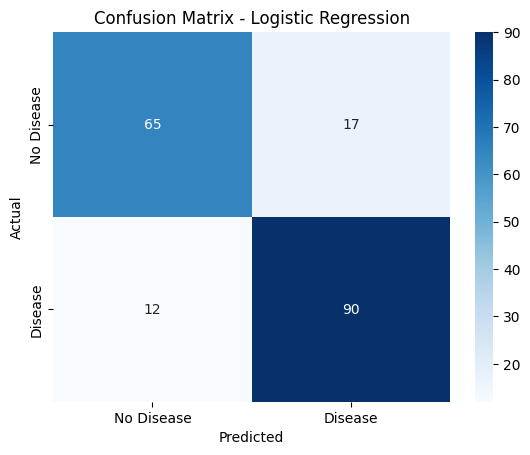

In [21]:
cm = confusion_matrix(y_test, lr_pred)

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["No Disease", "Disease"],
    yticklabels=["No Disease", "Disease"]
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix - Logistic Regression")
plt.show()

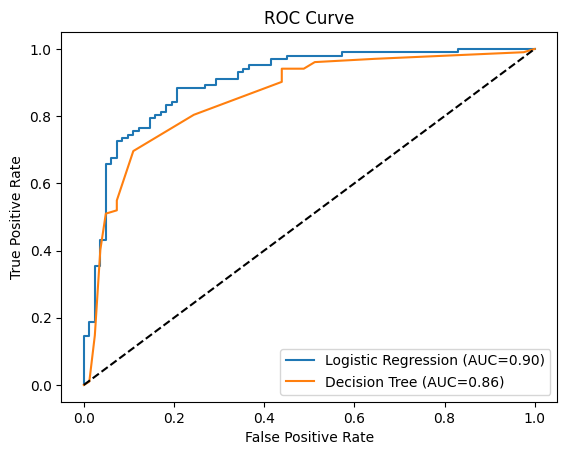

In [22]:
lr_prob = lr_model.predict_proba(X_test)[:, 1]
dt_prob = dt_model.predict_proba(X_test)[:, 1]

lr_fpr, lr_tpr, _ = roc_curve(y_test, lr_prob)
dt_fpr, dt_tpr, _ = roc_curve(y_test, dt_prob)

lr_auc = roc_auc_score(y_test, lr_prob)
dt_auc = roc_auc_score(y_test, dt_prob)

plt.plot(lr_fpr, lr_tpr, label=f"Logistic Regression (AUC={lr_auc:.2f})")
plt.plot(dt_fpr, dt_tpr, label=f"Decision Tree (AUC={dt_auc:.2f})")

plt.plot([0, 1], [0, 1], "k--")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve")
plt.legend()
plt.show()

In [23]:
print("Logistic Regression Report:")
print(classification_report(y_test, lr_pred, zero_division=0))

print("Decision Tree Report:")
print(classification_report(y_test, dt_pred, zero_division=0))

Logistic Regression Report:
              precision    recall  f1-score   support

           0       0.84      0.79      0.82        82
           1       0.84      0.88      0.86       102

    accuracy                           0.84       184
   macro avg       0.84      0.84      0.84       184
weighted avg       0.84      0.84      0.84       184

Decision Tree Report:
              precision    recall  f1-score   support

           0       0.76      0.76      0.76        82
           1       0.80      0.80      0.80       102

    accuracy                           0.78       184
   macro avg       0.78      0.78      0.78       184
weighted avg       0.78      0.78      0.78       184

